In [1]:
import matplotlib.pyplot as plt
%load_ext autoreload
%autoreload 2
from priors.alpha_prior import get_d2g_alpha
from priors.transition_prior import TransitionPrior
import pymc as pm
import models.model_utils as u

from models.mm_mode_region_independent import MarkovModeRegionIndependent



# Markov model with independent matrices for region and mode

1. Pick `region`
2. Pick a mode `m`. The choice depends on the region. Mode preferences by region are represented by `nu`
3. Use the Transition Matrix `A_r_m` of Region `region` and mode `m`. Transition Matrix is a 4-dim tensor R x M x AlphabetSize x AlphabetSize
4. Pick `x_0`
5. Pick `x_t`...

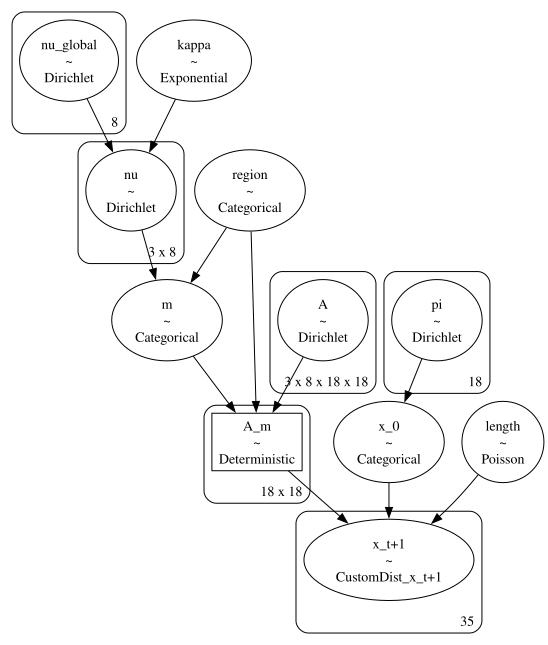

In [2]:
model = MarkovModeRegionIndependent()
model.alpha = get_d2g_alpha(model.V)

beta = TransitionPrior(model.V)

beta.prefer_small_intervals(5,1)
beta.prefer_low_register(1,2,2)
beta.penalize_repeated_notes(0.3)
beta.offset(2)
model.beta = beta.get_beta()
model.build_model()
pm.model_to_graphviz(model.model)

In [3]:
import data.GradualePipeline as gp
data = gp.GradualePipeline.load("data/processed/dataset_pitches_modes_regions.pkl")
data 

{'x_0_obs': array([ 6,  7,  7,  2,  6,  3,  7,  5,  6,  3,  5,  5,  5,  3,  5,  3,  3,
         4,  6,  3,  3,  6,  5,  6,  7,  5,  4,  2,  6,  5,  5,  3,  3,  6,
         9,  5,  5,  7,  6,  7,  3,  3,  6,  6,  5,  9,  3,  7,  9,  3,  3,
         5,  3,  6,  8,  6,  8,  6, 10,  6,  5,  3,  9,  6,  9,  8,  6,  5,
         3,  4,  3,  9,  9,  3,  7,  2,  9,  3,  3,  2,  6,  2,  3,  2,  3,
         6,  3,  3,  3,  7,  6,  5,  6,  5,  3,  7,  5,  7,  6,  6,  5,  9,
         6,  3,  5,  3,  7,  5,  7,  7,  3,  4,  5,  9,  9,  3,  3,  4,  9,
         6,  3,  7,  5,  6,  3,  5,  7,  5,  7,  9,  3,  6,  3,  3]),
 'x_t_obs': array([[ 6,  7,  6, ...,  6,  5,  5],
        [ 7,  7,  5, ...,  5,  5,  3],
        [ 8,  6,  6, ...,  5,  6,  3],
        ...,
        [-1, -1, -1, ..., -1, -1, -1],
        [-1, -1, -1, ..., -1, -1, -1],
        [-1, -1, -1, ..., -1, -1, -1]], shape=(428, 134)),
 'lengths_obs': array([385, 201, 104,  80, 222, 211, 140, 158, 219, 279, 260,  98, 145,
        103, 109, 154

In [4]:
trace = model.fit(data,use_latest=True,description="First try")

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [nu_global, kappa, nu, A, pi]


Output()

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 2562 seconds.
There were 632 divergences after tuning. Increase `target_accept` or reparameterize.
The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details


In [5]:
trace.posterior

<xarray.Dataset> Size: 250MB
Dimensions:          (chain: 4, draw: 1000, nu_global_dim_0: 8, nu_dim_0: 3,
                      nu_dim_1: 8, A_dim_0: 3, A_dim_1: 8, A_dim_2: 18,
                      A_dim_3: 18, pi_dim_0: 18)
Coordinates:
  * chain            (chain) int64 32B 0 1 2 3
  * draw             (draw) int64 8kB 0 1 2 3 4 5 6 ... 994 995 996 997 998 999
  * nu_global_dim_0  (nu_global_dim_0) int64 64B 0 1 2 3 4 5 6 7
  * nu_dim_0         (nu_dim_0) int64 24B 0 1 2
  * nu_dim_1         (nu_dim_1) int64 64B 0 1 2 3 4 5 6 7
  * A_dim_0          (A_dim_0) int64 24B 0 1 2
  * A_dim_1          (A_dim_1) int64 64B 0 1 2 3 4 5 6 7
  * A_dim_2          (A_dim_2) int64 144B 0 1 2 3 4 5 6 ... 11 12 13 14 15 16 17
  * A_dim_3          (A_dim_3) int64 144B 0 1 2 3 4 5 6 ... 11 12 13 14 15 16 17
  * pi_dim_0         (pi_dim_0) int64 144B 0 1 2 3 4 5 6 ... 12 13 14 15 16 17
Data variables:
    nu_global        (chain, draw, nu_global_dim_0) float64 256kB 0.1091 ... ...
    kappa            (chain, draw) float64 32kB 14.74 5.657 ... 10.14 10.79
    nu               (chain, draw, nu_dim_0, nu_dim_1) float64 768kB 0.1302 ....
    A                (chain, draw, A_dim_0, A_dim_1, A_dim_2, A_dim_3) float64 249MB ...
    pi               (chain, draw, pi_dim_0) float64 576kB 2.474e-09 ... 2.89...
Attributes:
    created_at:                 2026-04-07T09:46:41.305153+00:00
    arviz_version:              0.23.4
    inference_library:          pymc
    inference_library_version:  5.28.1
    sampling_time:              2562.4840297698975
    tuning_steps:               1000

In [9]:
import os
import itertools
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import arviz as az
from pathlib import Path

def _generate_pitch_labels(v_size):
    base_notes = ["A", "B", "C", "D", "E", "F", "G"]
    labels = []
    for i in range(v_size):
        octave = i // 7
        note = base_notes[i % 7]
        if octave == 0:
            labels.append(note)
        else:
            labels.append(note.lower() * octave)
    return labels

def _extract_summary_stats(idata, var_name):
    posterior = idata.posterior[var_name]
    mean_vals = posterior.mean(dim=["chain", "draw"]).values
    std_vals = posterior.std(dim=["chain", "draw"]).values
    return mean_vals, std_vals

def _calculate_figsize(v_size, num_plots=1):
    base_size = max(6.0, v_size * 0.5)
    return (base_size * num_plots, base_size * 0.85)

def _draw_annotated_heatmap(mean_vals, ax, title, cmap="viridis", center=None, v_labels=None):
    sns.heatmap(
        mean_vals,
        cmap=cmap,
        ax=ax,
        center=center,
        xticklabels=v_labels if v_labels is not None else "auto",
        yticklabels=v_labels if v_labels is not None else "auto",
        cbar_kws={"label": "Posterior Mean"},
        square=True,
        annot=False # Für Übersichtlichkeit deaktiviert
    )
    ax.set_title(title)
    ax.set_xlabel("To State (t)")
    ax.set_ylabel("From State (t-1)")

def plot_transition_matrices(idata, v_size, region_idx=0, m_labels=None, r_labels=None):
    v_labels = _generate_pitch_labels(v_size)
    mean_vals, _ = _extract_summary_stats(idata, "A")
    M = mean_vals.shape[1]
    
    region_name = r_labels[region_idx]
    fig, axes = plt.subplots(1, M, figsize=_calculate_figsize(v_size, M))
    if M == 1: axes = [axes]
        
    for m, ax in enumerate(axes):
        _draw_annotated_heatmap(
            mean_vals[region_idx, m], 
            ax, 
            title=f"{m_labels[m]}\n({region_name})", 
            cmap="Blues", 
            v_labels=v_labels
        )
        
    plt.tight_layout()
    return fig

def plot_region_differences_grid(idata, v_size, region_a_idx, region_b_idx, m_labels, r_labels):
    v_labels = _generate_pitch_labels(v_size)
    mean_vals, _ = _extract_summary_stats(idata, "A")
    M = mean_vals.shape[1]
    
    reg_a_name = r_labels[region_a_idx]
    reg_b_name = r_labels[region_b_idx]
    
    fig, axes = plt.subplots(1, M, figsize=_calculate_figsize(v_size, M))
    if M == 1: axes = [axes]
        
    for m, ax in enumerate(axes):
        diff_mean = mean_vals[region_a_idx, m] - mean_vals[region_b_idx, m]
        _draw_annotated_heatmap(
            diff_mean, 
            ax, 
            title=f"Diff: {reg_a_name} - {reg_b_name}\n({m_labels[m]})", 
            cmap="coolwarm", # Rot = Region A dominiert, Blau = Region B dominiert
            center=0,
            v_labels=v_labels
        )
        
    plt.tight_layout()
    return fig

def plot_mode_differences(idata, v_size, region_idx, mode_a_idx, mode_b_idx, m_labels, r_labels):
    v_labels = _generate_pitch_labels(v_size)
    mean_vals, _ = _extract_summary_stats(idata, "A")
    
    reg_name = r_labels[region_idx]
    mode_a_name = m_labels[mode_a_idx]
    mode_b_name = m_labels[mode_b_idx]
    
    diff_mean = mean_vals[region_idx, mode_a_idx] - mean_vals[region_idx, mode_b_idx]
    
    fig, ax = plt.subplots(figsize=_calculate_figsize(v_size, 1))
    _draw_annotated_heatmap(
        diff_mean, 
        ax, 
        title=f"Diff: {mode_a_name} - {mode_b_name}\n({reg_name})", 
        cmap="PiYG", # Pink/Grün für Modus-Differenzen zur visuellen Trennung
        center=0,
        v_labels=v_labels
    )
    plt.tight_layout()
    return fig

def plot_mode_probabilities(idata, r_labels):
    fig, ax = plt.subplots(figsize=(10, 6))
    nu_mean, _ = _extract_summary_stats(idata, "nu")
    R, M = nu_mean.shape
    
    modes = np.arange(1, M + 1)
    for r in range(R):
        ax.plot(modes, nu_mean[r], marker='o', label=r_labels[r], linewidth=2)
        
    ax.set_title("Mode Probabilities (nu) per Region")
    ax.set_xlabel("Mode")
    ax.set_ylabel("Probability")
    ax.set_xticks(modes)
    ax.legend()
    ax.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    return fig

def generate_all_visualizations(idata, v_size, r_labels=None, m_labels=None, save_dir="visualizations", exhaustive_modes=False):
    """
    Orchestriert die Erstellung und Speicherung aller Plots in einer sauberen Ordnerstruktur.
    """
    # Defaults setzen
    r_labels = r_labels or ["West", "East", "Italy"]
    m_labels = m_labels or [f"Mode {m}" for m in range(1, 9)]
    R, M = len(r_labels), len(m_labels)
    
    base_path = Path(save_dir)
    dirs = {
        "absolute": base_path / "1_absolute_matrices",
        "regional_diff": base_path / "2_regional_differences",
        "probs": base_path / "3_probabilities",
        "mode_diff": base_path / "4_mode_differences"
    }
    
    for d in dirs.values():
        d.mkdir(parents=True, exist_ok=True)
        
    print(f"Generiere Plots im Verzeichnis: {base_path.absolute()}")

    # 1. Globale Modus-Wahrscheinlichkeiten
    print("-> Generiere Modus-Wahrscheinlichkeiten...")
    fig = plot_mode_probabilities(idata, r_labels)
    fig.savefig(dirs["probs"] / "mode_probabilities.png", dpi=200, bbox_inches="tight")
    plt.close(fig)

    # 2. Absolute Matrizen (Pro Region alle Modi)
    print("-> Generiere absolute Übergangsmatrizen...")
    for r_idx in range(R):
        fig = plot_transition_matrices(idata, v_size, r_idx, m_labels, r_labels)
        fig.savefig(dirs["absolute"] / f"absolute_matrices_{r_labels[r_idx]}.png", dpi=200, bbox_inches="tight")
        plt.close(fig)

    # 3. Regionale Differenzen (Alle Kombinationen von Regionen)
    print("-> Generiere regionale Differenz-Plots...")
    region_pairs = list(itertools.combinations(range(R), 2))
    for (r_a, r_b) in region_pairs:
        fig = plot_region_differences_grid(idata, v_size, r_a, r_b, m_labels, r_labels)
        filename = f"diff_region_{r_labels[r_a]}_vs_{r_labels[r_b]}.png"
        fig.savefig(dirs["regional_diff"] / filename, dpi=200, bbox_inches="tight")
        plt.close(fig)

    # 4. Modus Differenzen (Exhaustiv, falls aktiviert)
    if exhaustive_modes:
        print("-> Generiere exhaustive Modus-Differenz-Plots (Das kann einen Moment dauern)...")
        mode_pairs = list(itertools.combinations(range(M), 2))
        for r_idx in range(R):
            reg_dir = dirs["mode_diff"] / r_labels[r_idx]
            reg_dir.mkdir(exist_ok=True)
            for (m_a, m_b) in mode_pairs:
                fig = plot_mode_differences(idata, v_size, r_idx, m_a, m_b, m_labels, r_labels)
                filename = f"diff_mode_{m_labels[m_a]}_vs_{m_labels[m_b]}.png"
                fig.savefig(reg_dir / filename, dpi=150, bbox_inches="tight")
                plt.close(fig)

    print("Alle Visualisierungen erfolgreich gespeichert!")

# Ausführungsbeispiel:
generate_all_visualizations(
idata=trace, 
v_size=len(model.alphabet), 
save_dir="visual/4_posterior",
exhaustive_modes=True # Setze auf True, um alle 84 Modus-Paarungen zu plotten
)

Generiere Plots im Verzeichnis: /Users/timeipert/PycharmProjects/generative_medieval_music_model/visual/4_posterior
-> Generiere Modus-Wahrscheinlichkeiten...
-> Generiere absolute Übergangsmatrizen...
-> Generiere regionale Differenz-Plots...
-> Generiere exhaustive Modus-Differenz-Plots (Das kann einen Moment dauern)...
Alle Visualisierungen erfolgreich gespeichert!
